# Agent的基本使用

## 1、Agent中模型的传入方式

### 1.1 传入字符串

In [1]:
from dotenv import load_dotenv
from langchain.agents import create_agent

load_dotenv(override=True)

agent = create_agent(
    model= "deepseek:deepseek-v4-flash"   # 调用的是ChatDeepSeek()
)

print(type(agent))

<class 'langgraph.graph.state.CompiledStateGraph'>


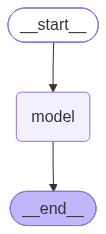

In [2]:
from IPython.display import Image, display
display(Image(agent.get_graph().draw_mermaid_png()))

也可以显式使用 ChatOpenRouter

In [3]:
from dotenv import load_dotenv
from langchain.agents import create_agent
from langchain_openrouter import ChatOpenRouter

load_dotenv(override=True)

model = ChatOpenRouter(
    model="openai/gpt-4o-mini",
    temperature=0
)

agent = create_agent(model=model)

print(type(model))
print(type(agent))

<class 'langchain_openrouter.chat_models.ChatOpenRouter'>
<class 'langgraph.graph.state.CompiledStateGraph'>


In [8]:
from langchain.chat_models import init_chat_model
from dotenv import load_dotenv
import os

# 从.env文件中加载环境变量
load_dotenv(override=True)

CLOSEAI_API_KEY = os.getenv("CLOSEAI_API_KEY")
CLOSEAI_BASE_URL = os.getenv("CLOSEAI_BASE_URL")

model = init_chat_model(
    model="gpt-5.4-mini",
    model_provider="openai",
    api_key=CLOSEAI_API_KEY,
    base_url=CLOSEAI_BASE_URL
)

agent = create_agent(model=model)

print(type(model))
print(type(agent))

<class 'langchain_openai.chat_models.base.ChatOpenAI'>
<class 'langgraph.graph.state.CompiledStateGraph'>


## 2、如何调用Agent

举例1：

In [ ]:
from langchain.agents import create_agent
from langchain.chat_models import init_chat_model
from dotenv import load_dotenv
import os
load_dotenv(override=True)
from rich import print as rprint

# 以init_chat_model为例
model = init_chat_model(
    model="gpt-5.4-mini",
    model_provider="openai",
    api_key=os.getenv("CLOSEAI_API_KEY"),
    base_url=os.getenv("CLOSEAI_BASE_URL")
)



agent = create_agent(
    model=model
)

# 调用
response= agent.invoke({
    "messages":[
        {"role":"user","content":"你好"}
    ]
})

# response= agent.invoke({
#     "messages":[
#         "你好"
#     ]
# })

rprint(response)

举例2：

In [10]:
from langchain.agents import create_agent
from langchain.chat_models import init_chat_model
from dotenv import load_dotenv
import os
load_dotenv(override=True)
from rich import print as rprint

# 以init_chat_model为例
model = init_chat_model(
    model="gpt-5.4-mini",
    model_provider="openai",
    api_key=os.getenv("CLOSEAI_API_KEY"),
    base_url=os.getenv("CLOSEAI_BASE_URL")
)



agent = create_agent(
    model=model
)

# 调用
response= agent.invoke({
    "messages":[
        {"role":"system","content":"你是一个精通数学的老师，擅长以通俗易懂的方式讲解数学问题"},
        {"role":"user","content":"100 + 20 * 3 = ？"}
    ]
})


rprint(response)

{
    'messages': [
        SystemMessage(
            content='你是一个精通数学的老师，擅长以通俗易懂的方式讲解数学问题',
            additional_kwargs={},
            response_metadata={},
            id='927f974f-4bf2-4de8-ac84-e65ffe89a1fb'
        ),
        HumanMessage(
            content='100 + 20 * 3 = ？',
            additional_kwargs={},
            response_metadata={},
            id='141dfd9b-486f-438c-a2dd-b1ac05ac27bd'
        ),
        AIMessage(
            content='先算乘法，再算加法：\n\n- \\(20 \\times 3 = 60\\)\n- \\(100 + 60 = 160\\)\n\n所以答案是 
**160**。',
            additional_kwargs={'refusal': None},
            response_metadata={
                'token_usage': {
                    'completion_tokens': 42,
                    'prompt_tokens': 43,
                    'total_tokens': 85,
                    'completion_tokens_details': {
                        'accepted_prediction_tokens': 0,
                        'audio_tokens': 0,
                        'reasoning_tokens': 0,
                        'rejected_prediction_tokens': 0
                    },
                    'prompt_tokens_details': {'audio_tokens': 0, 'cached_tokens': 0},
                    'latency_checkpoint': {
                        'engine_tbt_ms': 7,
                        'engine_ttft_ms': 44,
                        'engine_ttlt_ms': 337,
                        'pre_inference_ms': 122,
                        'service_tbt_ms': 7,
                        'service_ttft_ms': 545,
                        'service_ttlt_ms': 841,
                        'user_visible_ttft_ms': 423
                    }
                },
                'model_provider': 'openai',
                'model_name': 'gpt-5.4-mini-2026-03-17',
                'system_fingerprint': None,
                'id': 'chatcmpl-Eg8GApXlshvYPL1OcCgp9RuvTH5hM',
                'service_tier': 'default',
                'finish_reason': 'stop',
                'logprobs': None
            },
            id='lc_run--01a1a176-16f8-75ae-ad54-3c2b6f39b1ee-0',
            tool_calls=[],
            invalid_tool_calls=[],
            usage_metadata={
                'input_tokens': 43,
                'output_tokens': 42,
                'total_tokens': 85,
                'input_token_details': {'audio': 0, 'cache_read': 0},
                'output_token_details': {'audio': 0, 'reasoning': 0}
            }
        )
    ]
}

## 3、如何绑定工具，并调用工具

### 举例1：绑定一个自定义的工具

In [ ]:

from langchain_core.tools import tool
from langchain.agents import create_agent
from langchain.chat_models import init_chat_model
from dotenv import load_dotenv
import os
load_dotenv(override=True)
from rich import print as rprint

# 以init_chat_model为例
model = init_chat_model(
    model="gpt-5.4-mini",
    model_provider="openai",
    api_key=os.getenv("CLOSEAI_API_KEY"),
    base_url=os.getenv("CLOSEAI_BASE_URL")
)

# 定义一个工具
@tool(parse_docstring=True)
def get_weather(city : str):
    """
    查询天气的工具

    Args:
        city : 具体的城市
    """
    return f"{city}天气晴朗，温度是15℃"


agent = create_agent(
    model = model,
    tools = [get_weather]
)


response = agent.invoke({
    "messages" : [
        {"role":"system","content":"你是一个查询天气的助手，根据用户的提问查询天气。如果问题跟天气无关，你可以说：我不清楚这个问题的答案"},
        {"role":"user","content":"北京的天气如何？"}
    ]
})

rprint(response)

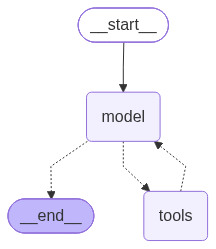

In [12]:
from IPython.display import Image, display
display(Image(agent.get_graph().draw_mermaid_png()))

### 举例2：调用langchain内置的工具

In [13]:

from langchain_tavily import TavilySearch
from langchain_core.tools import tool
from langchain.agents import create_agent
from langchain.chat_models import init_chat_model
from dotenv import load_dotenv
import os
load_dotenv(override=True)
from rich import print as rprint

# 以init_chat_model为例
model = init_chat_model(
    model="gpt-5.4-mini",
    model_provider="openai",
    api_key=os.getenv("CLOSEAI_API_KEY"),
    base_url=os.getenv("CLOSEAI_BASE_URL")
)

# 使用内置的工具
web_search = TavilySearch(
    max_results=2,
    tavily_api_key=os.getenv("TAVILY_API_KEY"),
)


agent = create_agent(
    model = model,
    tools = [web_search]
)


response = agent.invoke({
    "messages" : [
        {"role": "user", "content": "请帮我查询2024年诺贝尔物理学奖得主是谁？"}
    ]
})

rprint(response)

{
    'messages': [
        HumanMessage(
            content='请帮我查询2024年诺贝尔物理学奖得主是谁？',
            additional_kwargs={},
            response_metadata={},
            id='a0f9ebf6-e518-499b-a15a-d36b98f7201b'
        ),
        AIMessage(
            content='',
            additional_kwargs={'refusal': None},
            response_metadata={
                'token_usage': {
                    'completion_tokens': 52,
                    'prompt_tokens': 1286,
                    'total_tokens': 1338,
                    'completion_tokens_details': {
                        'accepted_prediction_tokens': 0,
                        'audio_tokens': 0,
                        'reasoning_tokens': 0,
                        'rejected_prediction_tokens': 0
                    },
                    'prompt_tokens_details': {'audio_tokens': 0, 'cached_tokens': 0},
                    'latency_checkpoint': {
                        'engine_tbt_ms': 5,
                        'engine_ttft_ms': 69,
                        'engine_ttlt_ms': 329,
                        'pre_inference_ms': 76,
                        'service_tbt_ms': 5,
                        'service_ttft_ms': 572,
                        'service_ttlt_ms': 828,
                        'user_visible_ttft_ms': 496
                    }
                },
                'model_provider': 'openai',
                'model_name': 'gpt-5.4-mini-2026-03-17',
                'system_fingerprint': None,
                'id': 'chatcmpl-Eg8UNqhQqVlzt4KcpUPpOXrjkijrk',
                'service_tier': 'default',
                'finish_reason': 'tool_calls',
                'logprobs': None
            },
            id='lc_run--01a1a183-877e-7703-93df-847bbd4f8fab-0',
            tool_calls=[
                {
                    'name': 'tavily_search',
                    'args': {
                        'query': '2024 诺贝尔物理学奖 得主 官方',
                        'search_depth': 'advanced',
                        'topic': 'general',
                        'include_domains': ['nobelprize.org']
                    },
                    'id': 'call_w1OltlzsumEo6cgfBnIlQtLM',
                    'type': 'tool_call'
                }
            ],
            invalid_tool_calls=[],
            usage_metadata={
                'input_tokens': 1286,
                'output_tokens': 52,
                'total_tokens': 1338,
                'input_token_details': {'audio': 0, 'cache_read': 0},
                'output_token_details': {'audio': 0, 'reasoning': 0}
            }
        ),
        ToolMessage(
            content='{"query": "2024 诺贝尔物理学奖 得主 官方", "follow_up_questions": null, "answer": null, 
"images": [], "results": [{"url": "https://www.nobelprize.org/prizes/lists/all-nobel-prizes-in-physics/all", 
"title": "All Nobel Prizes in Physics - NobelPrize.org", "content": "### Nobel Prize in Physics 2025\\n\\nJohn 
Clarke,  Michel H. Devoret and  John M. Martinis\\n\\n> “for the discovery of macroscopic quantum mechanical 
tunnelling and energy quantisation in an electric circuit”\\n\\n### Nobel Prize in Physics 2024\\n\\nJohn J. 
Hopfield and  Geoffrey Hinton\\n\\n> “for foundational discoveries and inventions that enable machine learning with
artificial neural networks”\\n\\n### Nobel Prize in Physics 2023\\n\\nPierre Agostini,  Ferenc Krausz and  Anne 
L’Huillier\\n\\n> “for experimental methods that generate attosecond pulses of light for the study of electron 
dynamics in matter”\\n\\n### Nobel Prize in Physics 2022\\n\\nAlain Aspect,  John Clauser and  Anton Zeilinger 
[...] Skip to content \\n\\n# Nobel Prize\\n\\n# All Nobel Prizes in Physics\\n\\nThe Nobel Prize in Physics has 
been awarded 120 times to 231 Nobel Prize laureates between 1901 and 2026. John Bardeen is the only laureate who 
has been awarded the Nobel Prize in Physics twice, in 1956 and 1972. This means that a total of 230 individuals 
have received the Nobel Prize in Physics. Click on the links to get mor

### 举例3：绑定多个工具，并调用

In [ ]:
from langchain.agents import create_agent
from langchain.tools import tool
from dotenv import load_dotenv
from rich import print as rprint

load_dotenv(override=True)

@tool(parse_docstring=True)
def get_weather(city: str):
    """
    天气查询工具

    Args:
        city: 城市名称
    """
    return f"{city}今天天气挺好"

@tool(parse_docstring=True)
def get_news():
    """
    新闻查询工具
    """
    return "近期，受全球储蓄芯片短缺等多重因素影响，多地回收商称废旧手机回收市场迎来“火热潮”，回收价格普遍上涨，旧手机成“香饽饽”。"

agent = create_agent(
    model,
    tools=[get_weather, get_news]
)
response = agent.invoke({
    "messages": ["你好，杭州今天的天气如何？今天有哪些新闻？"]
})

rprint(response)


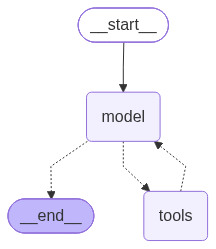

In [15]:
from IPython.display import Image, display
display(Image(agent.get_graph().draw_mermaid_png()))

## 4、重试机制

举例

In [16]:
from langchain.agents import create_agent
from langchain.tools import tool
from langchain.messages import SystemMessage, HumanMessage
from dotenv import load_dotenv
from rich import print as rprint

load_dotenv(override=True)

flag = 0

@tool
def get_weather(city: str):
    """
    天气查询工具

    Args:
        city: 城市名称
    """
    global flag
    flag += 1

    if flag < 3:
        # raise Exception("暂时无法访问")
        return "TEMP_UNAVAILABLE: 天气服务暂时不可用，请稍后重试"

    return f"{city}今天天气挺好"


messages = [
    SystemMessage("""
    你是一个天气助手。
    当工具返回以 'TEMP_UNAVAILABLE:' 开头的结果时，
    说明是临时故障，不要立即放弃；
    你应再次调用同一个工具，最多重试 3 次。
    如果 3 次后仍失败，再向用户说明服务暂时不可用。
    """),
    HumanMessage("你好，杭州今天的天气如何？")
]
agent = create_agent(model, tools=[get_weather])
response = agent.invoke({"messages": messages})

# rprint(response)

for msg in response["messages"]:
    msg.pretty_print()

================================ System Message ================================


    你是一个天气助手。
    当工具返回以 'TEMP_UNAVAILABLE:' 开头的结果时，
    说明是临时故障，不要立即放弃；
    你应再次调用同一个工具，最多重试 3 次。
    如果 3 次后仍失败，再向用户说明服务暂时不可用。
    
================================ Human Message =================================

你好，杭州今天的天气如何？
================================== Ai Message ==================================
Tool Calls:
  get_weather (call_qcMs65BapNBEOHM91pzHg9Qy)
 Call ID: call_qcMs65BapNBEOHM91pzHg9Qy
  Args:
    city: 杭州
================================= Tool Message =================================
Name: get_weather

TEMP_UNAVAILABLE: 天气服务暂时不可用，请稍后重试
================================== Ai Message ==================================
Tool Calls:
  get_weather (call_LuNEi1fHRRLjB748n3Nw4ILT)
 Call ID: call_LuNEi1fHRRLjB748n3Nw4ILT
  Args:
    city: 杭州
================================= Tool Message =================================
Name: get_weather

TEMP_UNAVAILABLE: 天气服务暂时不可用，请稍后重试
===================